# Lab 2.4 — Implementing PPO from Scratch · **INSTRUCTOR SOLUTION**

**Intelligent Agents · UC2 · 2.4 Policy Gradient Methods / Proximal Policy Optimization**

This notebook contains the complete reference implementation, the expected test results and model answers for every question. The student version (`PPO_Lab_Student.ipynb`) has the same structure, with `TODO` blocks in place of the solutions.

> **Instructor notes** are marked with 🧑‍🏫 throughout.

## Learning objectives

By the end of this lab you will be able to:

1. Build an **actor–critic** network whose actor outputs a probability distribution over actions (lecture §01, *Policy Gradient*).
2. Compute the **probability ratio** $r_t(\theta)=\pi_\theta(a_t|s_t)/\pi_{\theta_{old}}(a_t|s_t)$.
3. Implement **Generalized Advantage Estimation (GAE)** and check it against the worked example from the slides (lecture §02).
4. Implement the **clipped surrogate objective** and verify its *six cases* (lecture §03).
5. Assemble the full PPO loop — *Collect → Estimate → Optimize → Sync* — following **Algorithm 21** (Hu, 2023) (lecture §04).
6. Train an agent on **CartPole-v1** and run experiments on $\varepsilon$ and $\lambda$.

### The algorithm you will implement (Algorithm 21, Hu 2023)

```
Require: γ, α, β, N, ε, M, K
Initialize θ, θ_old ← θ, ψ
while environment steps < K:
    Collect N transitions (s_t, a_t, r_t, π(a_t|s_t; θ_old))          ← Part 5
    Compute returns G_t and GAE advantages Â_t                        ← Part 3
    for epoch p = 0 … M−1:
        θ ← θ + α ∇θ Σ min( r_t(θ) Â_t , clip(r_t(θ), 1−ε, 1+ε) Â_t )  ← Parts 2, 4, 6
        ψ ← ψ − β ∇ψ Σ (G_t − V(s_t; ψ))²                             ← Part 4
    θ_old ← θ                                                         ← Part 6
```

### How this lab is organised

| Part | Topic (slides) | TODOs | Points |
|---|---|---|---|
| 1 | Actor–critic network (§01, slides 5, 11) | 1.1, 1.2 | 15 |
| 2 | Probability ratio (§03, slide 18) | 2.1 | 5 |
| 3 | GAE (§02, slides 14–15) | 3.1 | 20 |
| 4 | Clipped surrogate + full loss (§03, slides 20–23) | 4.1, 4.2 | 20 |
| 5 | Rollout collection (§04, slide 26 — *Collect*) | 5.1 | 10 |
| 6 | PPO update (§04, slide 25 — lines 4–8) | 6.1 | 15 |
| 7 | Training and experiments | 7.1, 7.2 | 15 |
| | **Total** | | **100** |

Every TODO is followed by a **✅ check cell**. Run it: if it prints `PASSED`, move on.

> 💡 Work top to bottom and do not skip check cells — later parts reuse your earlier functions.

## 0 · Setup

Run the cells below. On Google Colab, PyTorch is pre-installed; the first cell installs Gymnasium if needed.

In [1]:
# Install dependencies if they are missing (Colab / local)
import importlib, subprocess, sys
for pkg in ["gymnasium", "torch", "matplotlib"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [2]:
import os

os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')

import random, time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical
import gymnasium as gym
import matplotlib.pyplot as plt

def set_seed(seed: int = 1):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

set_seed(1)
device = torch.device("cpu")   # CartPole is small: the CPU is faster than a GPU here
print("torch", torch.__version__, "| gymnasium", gym.__version__)

torch 2.14.0 | gymnasium 1.0.0


### 0.1 · Meet the environment: CartPole-v1

A pole is attached to a cart. **State** (4 numbers): cart position, cart velocity, pole angle, pole angular velocity. **Actions** (2): push left / push right. **Reward:** +1 for every step the pole stays up. An episode ends when the pole falls or after 500 steps, so **the maximum return is 500**.

In [3]:
env = gym.make("CartPole-v1")
obs, info = env.reset(seed=0)
print("observation space:", env.observation_space)
print("action space     :", env.action_space)
print("first observation:", obs)

# A random policy, for reference
returns = []
for ep in range(20):
    obs, _ = env.reset(seed=ep); done, ep_ret = False, 0.0
    while not done:
        obs, r, term, trunc, _ = env.step(env.action_space.sample())
        ep_ret += r; done = term or trunc
    returns.append(ep_ret)
print(f"random policy: mean return = {np.mean(returns):.1f}  (goal: close to 500)")
env.close()

observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
action space     : Discrete(2)
first observation: [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]
random policy: mean return = 19.4  (goal: close to 500)


### 0.2 · Provided helper: several environments in parallel

PPO collects experience from several copies of the environment at once. `MultiEnv` steps a list of environments and **automatically resets** any that finish, so the observation it returns after a `done` is already the first observation of the next episode. It also records the return of every finished episode. *You do not need to modify it.*

In [4]:
class MultiEnv:
    # Steps n copies of an environment and auto-resets finished episodes.
    def __init__(self, env_id: str, n: int, seed: int = 0):
        self.envs = [gym.make(env_id) for _ in range(n)]
        self.n, self.seed = n, seed
        self.obs_dim = self.envs[0].observation_space.shape[0]
        self.n_actions = self.envs[0].action_space.n
        self.ep_return = np.zeros(n)
        self.finished_returns = []           # returns of all completed episodes

    def reset(self):
        obs = [e.reset(seed=self.seed + i)[0] for i, e in enumerate(self.envs)]
        return np.array(obs, dtype=np.float32)

    def step(self, actions):
        obs, rewards, dones = [], [], []
        for i, (e, a) in enumerate(zip(self.envs, actions)):
            o, r, terminated, truncated, _ = e.step(int(a))
            self.ep_return[i] += r
            done = terminated or truncated
            if done:
                self.finished_returns.append(self.ep_return[i])
                self.ep_return[i] = 0.0
                o, _ = e.reset()
            obs.append(o); rewards.append(r); dones.append(float(done))
        return (np.array(obs, dtype=np.float32),
                np.array(rewards, dtype=np.float32),
                np.array(dones, dtype=np.float32))

    def close(self):
        for e in self.envs: e.close()

---
## Part 1 · The actor–critic network  *(15 pts)*

> **Slides 5 and 11.** The **actor** $\pi_\theta(a|s)$ outputs a probability for every action (a softmax over *logits*). The **critic** $V_\psi(s)$ outputs one number: how good the state is. Analogy: the *player* and the *coach*.

```
state s (4) ──► Linear(4,64) ─ tanh ─ Linear(64,64) ─ tanh ─ Linear(64, n_actions) ──► logits ──► Categorical ──► a
            └─► Linear(4,64) ─ tanh ─ Linear(64,64) ─ tanh ─ Linear(64, 1)         ──► V(s)
```

`layer_init` (provided) uses orthogonal initialisation, a standard PPO implementation detail. Note the small `std=0.01` for the actor's last layer: it makes the initial policy almost **uniform**, so the agent starts by exploring.

In [5]:
def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias_const)
    return layer

### TODO 1.1 — Build the two networks
Create `self.critic` and `self.actor` as `nn.Sequential` models following the diagram above (two hidden layers of `hidden` units with `nn.Tanh()`). Use `layer_init(...)` on every `nn.Linear`; use `std=1.0` for the critic's output layer and `std=0.01` for the actor's output layer.

### TODO 1.2 — `get_action_and_value`
1. Compute the logits with the actor and build `Categorical(logits=logits)`.
2. If `action is None`, **sample** an action from the distribution (this is how a stochastic policy explores).
3. Return `action`, `log_prob(action)`, `entropy()`, and the critic's value (shape `(batch,)`).

In [6]:
class Agent(nn.Module):
    def __init__(self, obs_dim: int, n_actions: int, hidden: int = 64):
        super().__init__()
        # TODO 1.1 (solution)
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, 1), std=1.0),
        )
        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, hidden)), nn.Tanh(),
            layer_init(nn.Linear(hidden, n_actions), std=0.01),
        )

    def get_value(self, x):
        return self.critic(x).squeeze(-1)

    def get_action_and_value(self, x, action=None):
        # TODO 1.2 (solution)
        logits = self.actor(x)
        dist = Categorical(logits=logits)
        if action is None:
            action = dist.sample()
        return action, dist.log_prob(action), dist.entropy(), self.get_value(x)

In [7]:
# ✅ Check Part 1
set_seed(0)
_agent = Agent(obs_dim=4, n_actions=2)
_x = torch.randn(8, 4)
_a, _lp, _ent, _v = _agent.get_action_and_value(_x)
assert _a.shape == (8,) and _lp.shape == (8,) and _ent.shape == (8,) and _v.shape == (8,), "check the output shapes: all should be (batch,)"
_probs = torch.exp(_agent.get_action_and_value(_x, torch.zeros(8, dtype=torch.long))[1]) \
       + torch.exp(_agent.get_action_and_value(_x, torch.ones(8, dtype=torch.long))[1])
assert torch.allclose(_probs, torch.ones(8), atol=1e-5), "probabilities over the 2 actions must sum to 1"
assert torch.allclose(_ent, torch.full((8,), np.log(2)), atol=1e-2), "initial policy should be ~uniform (entropy ≈ ln 2); did you use std=0.01 on the actor output?"
print("Initial action probabilities for one state:", torch.softmax(_agent.actor(_x[:1]), -1).detach().numpy().round(3))
print("PASSED ✔ Part 1")

Initial action probabilities for one state: [[0.502 0.498]]
PASSED ✔ Part 1


> 🧑‍🏫 **Instructor note.** The entropy check catches the most common mistake (forgetting `std=0.01`). Ask students why a near-uniform initial policy is desirable: it maximises exploration before the agent has learned anything (slide 5, the robot that "still explores the other moves").

**Question 1 — model answer.** Entropy $\ln 2$ is the maximum for two actions, so the initial policy is (almost) uniform: 50 % left, 50 % right. Starting uniform means maximum exploration and no premature preference for an action the agent knows nothing about.

---
## Part 2 · The probability ratio  *(5 pts)*

> **Slide 18.** $r_t(\theta) = \dfrac{\pi_\theta(a_t|s_t)}{\pi_{\theta_{old}}(a_t|s_t)}$. We store **log-probabilities**, so compute the ratio as $\exp(\log\pi_\theta - \log\pi_{\theta_{old}})$ — numerically safer than dividing small probabilities.

### TODO 2.1 — `prob_ratio`

In [8]:
def prob_ratio(new_logprob: torch.Tensor, old_logprob: torch.Tensor) -> torch.Tensor:
    # TODO 2.1 (solution)
    return torch.exp(new_logprob - old_logprob)

In [9]:
# ✅ Check Part 2 — the two examples from slide 18
r1 = prob_ratio(torch.log(torch.tensor(0.30)), torch.log(torch.tensor(0.25)))
r2 = prob_ratio(torch.log(torch.tensor(0.10)), torch.log(torch.tensor(0.25)))
print(f"0.30 / 0.25 = {r1.item():.3f}   (expected 1.200)")
print(f"0.10 / 0.25 = {r2.item():.3f}   (expected 0.400)")
assert abs(r1.item() - 1.2) < 1e-5 and abs(r2.item() - 0.4) < 1e-5
print("PASSED ✔ Part 2")

0.30 / 0.25 = 1.200   (expected 1.200)
0.10 / 0.25 = 0.400   (expected 0.400)
PASSED ✔ Part 2


---
## Part 3 · Generalized Advantage Estimation  *(20 pts)*

> **Slides 13–15.** TD error: $\delta_t = r_t + \gamma V(s_{t+1})(1-d_t) - V(s_t)$.
> GAE, computed **backward**: $\hat A_t = \delta_t + \gamma\lambda(1-d_t)\,\hat A_{t+1}$.
> Return target for the critic: $G_t = \hat A_t + V(s_t)$.

Here $d_t = 1$ if the episode **ended at step $t$** (after action $a_t$). The factor $(1-d_t)$ stops value from "leaking" across episode boundaries: the next state of a finished episode belongs to a *new* episode.

**Shapes.** `rewards`, `values`, `dones` are tensors of shape `(T, n_envs)`; `next_value` has shape `(n_envs,)` and is $V$ of the observation reached after the last step.

### TODO 3.1 — `compute_gae`
Loop `t` from `T-1` down to `0`:
1. `next_v` = `next_value` if `t == T-1`, else `values[t+1]`.
2. `nonterminal = 1 - dones[t]`.
3. `delta = rewards[t] + gamma * next_v * nonterminal - values[t]`.
4. `last_gae = delta + gamma * lam * nonterminal * last_gae`; store it in `advantages[t]`.

Then `returns = advantages + values`.

In [10]:
def compute_gae(rewards, values, dones, next_value, gamma=0.99, lam=0.95):
    T = rewards.shape[0]
    advantages = torch.zeros_like(rewards)
    last_gae = torch.zeros_like(next_value)
    # TODO 3.1 (solution)
    for t in reversed(range(T)):
        next_v = next_value if t == T - 1 else values[t + 1]
        nonterminal = 1.0 - dones[t]
        delta = rewards[t] + gamma * next_v * nonterminal - values[t]
        last_gae = delta + gamma * lam * nonterminal * last_gae
        advantages[t] = last_gae
    returns = advantages + values
    return advantages, returns

In [11]:
# ✅ Check Part 3 — the worked example from slide 15 (one environment, episode ends at t = 2)
rew = torch.tensor([[1.0], [0.0], [2.0]])
val = torch.tensor([[0.5], [0.8], [1.0]])
dns = torch.tensor([[0.0], [0.0], [1.0]])
nxt = torch.tensor([123.0])        # value of the *next* episode's first state: must be ignored!
adv, ret = compute_gae(rew, val, dns, nxt, gamma=0.99, lam=0.95)
print("advantages:", adv.squeeze().numpy().round(4), "  expected [2.3552 1.1305 1.    ]")
print("returns   :", ret.squeeze().numpy().round(4), "  expected [2.8552 1.9305 2.    ]")
assert torch.allclose(adv.squeeze(), torch.tensor([2.35523525, 1.1305, 1.0]), atol=1e-4)
assert torch.allclose(ret.squeeze(), torch.tensor([2.85523525, 1.9305, 2.0]), atol=1e-4)

# λ = 0 must reduce GAE to the one-step TD error (slide 13)
adv0, _ = compute_gae(rew, val, dns, nxt, gamma=0.99, lam=0.0)
assert torch.allclose(adv0.squeeze(), torch.tensor([1.292, 0.19, 1.0]), atol=1e-4), "with λ=0, Â_t should equal δ_t"
print("PASSED ✔ Part 3")

advantages: [2.3552 1.1305 1.    ]   expected [2.3552 1.1305 1.    ]
returns   : [2.8552 1.9305 2.    ]   expected [2.8552 1.9305 2.    ]
PASSED ✔ Part 3


**Question 2 — model answer.**
(a) With λ = 1 (γ = 0.99): $\hat A_2 = 1.000$, $\hat A_1 = 0.19 + 0.99 \cdot 1.0 = 1.180$, $\hat A_0 = 1.292 + 0.99 \cdot 1.18 = 2.460$. This equals the Monte-Carlo advantage $G_t - V(s_t)$: e.g. $G_0 = 1 + 0.99\cdot 0 + 0.99^2 \cdot 2 = 2.960$ and $2.960 - 0.5 = 2.460$.
(b) Step 1 has a small TD error (0.19) because nothing special happens immediately, but its action leads to the +2 reward at step 2; GAE propagates that later credit backward through the $\gamma\lambda\hat A_{t+1}$ term.

> 🧑‍🏫 Students can verify (a) with `compute_gae(rew, val, dns, nxt, lam=1.0)`.

In [12]:
# Space for Question 2 (a)
adv1, _ = compute_gae(rew, val, dns, nxt, gamma=0.99, lam=1.0)
print("λ = 1 advantages:", adv1.squeeze().numpy().round(4))

λ = 1 advantages: [2.4602 1.18   1.    ]


---
## Part 4 · The clipped surrogate objective and the full loss  *(20 pts)*

> **Slide 20.** $L^{CLIP}(\theta) = \hat{\mathbb E}\Big[\min\big(r_t(\theta)\hat A_t,\; \text{clip}(r_t(\theta), 1-\varepsilon, 1+\varepsilon)\,\hat A_t\big)\Big]$

PyTorch optimisers **minimise**, while we want to **maximise** $L^{CLIP}$, so the policy loss is $-L^{CLIP}$.

### TODO 4.1 — `clipped_surrogate_loss`
1. `ratio = prob_ratio(new_logprob, old_logprob)`
2. `unclipped = ratio * advantages`
3. `clipped = torch.clamp(ratio, 1 - clip_coef, 1 + clip_coef) * advantages`
4. return `-torch.min(unclipped, clipped).mean()`

In [13]:
def clipped_surrogate_loss(new_logprob, old_logprob, advantages, clip_coef=0.2):
    # TODO 4.1 (solution)
    ratio = prob_ratio(new_logprob, old_logprob)
    unclipped = ratio * advantages
    clipped = torch.clamp(ratio, 1 - clip_coef, 1 + clip_coef) * advantages
    return -torch.min(unclipped, clipped).mean()

### ✅ Check 4.1 — the six cases (slide 22)

For each case we set $\pi_{\theta_{old}} = 1$ (log-prob 0), choose a ratio $r$ and an advantage sign, and ask PyTorch for the gradient of the loss with respect to the new log-probability. **Cases 4 and 5 must give a zero gradient** (no update); the others must not.

In [14]:
cases = [  # (case, ratio, advantage, should_update)
    (1, 1.0, +1.0, True), (2, 1.0, -1.0, True),
    (3, 0.5, +1.0, True), (4, 0.5, -1.0, False),
    (5, 1.5, +1.0, False), (6, 1.5, -1.0, True),
]
print(f"{'case':>4} {'r':>5} {'Â':>5} {'gradient':>10}  update?")
for case, r, A, should_update in cases:
    new_lp = torch.tensor([np.log(r)], dtype=torch.float32, requires_grad=True)
    loss = clipped_surrogate_loss(new_lp, torch.zeros(1), torch.tensor([A]), clip_coef=0.2)
    loss.backward()
    g = new_lp.grad.item()
    updated = abs(g) > 1e-8
    print(f"{case:>4} {r:>5.1f} {A:>+5.0f} {g:>10.4f}  {'yes' if updated else 'no (0)'}")
    assert updated == should_update, f"case {case} is wrong — re-read slide 22"
print("PASSED ✔ Check 4.1")

case     r     Â   gradient  update?
   1   1.0    +1    -1.0000  yes
   2   1.0    -1     1.0000  yes
   3   0.5    +1    -0.5000  yes
   4   0.5    -1     0.0000  no (0)
   5   1.5    +1     0.0000  no (0)
   6   1.5    -1     1.5000  yes
PASSED ✔ Check 4.1


### 📈 Visualise your loss (slide 21)
This cell plots $L^{CLIP}$ as a function of $r$ using **your** function. It should reproduce the two plots from the lecture.

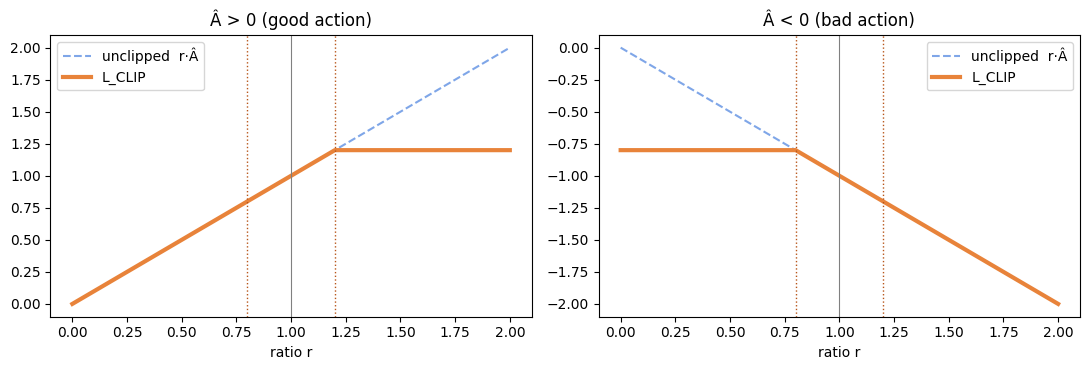

In [15]:
rs = torch.linspace(0.0, 2.0, 201)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, A, title in [(axes[0], 1.0, "Â > 0 (good action)"), (axes[1], -1.0, "Â < 0 (bad action)")]:
    L = [-clipped_surrogate_loss(torch.log(r).unsqueeze(0), torch.zeros(1), torch.tensor([A])).item() for r in rs]
    ax.plot(rs, (rs * A).numpy(), "--", color="#7FA6E8", label="unclipped  r·Â")
    ax.plot(rs, L, color="#E8833A", lw=3, label="L_CLIP")
    for x in (0.8, 1.2): ax.axvline(x, color="#B8561A", ls=":", lw=1)
    ax.axvline(1.0, color="gray", lw=0.8)
    ax.set_title(title); ax.set_xlabel("ratio r"); ax.legend(loc="best")
plt.tight_layout(); plt.show()

### TODO 4.2 — `ppo_loss`: the full actor–critic objective (slide 23)

$$\text{loss} = \underbrace{-L^{CLIP}}_{\text{policy}} \;+\; c_1 \underbrace{\tfrac12\,\hat{\mathbb E}\big[(G_t - V_\psi(s_t))^2\big]}_{\text{value loss}} \;-\; c_2 \underbrace{\hat{\mathbb E}\big[S[\pi_\theta](s_t)\big]}_{\text{entropy bonus}}$$

Return the total `loss` **and** a dictionary with the three components (as Python floats) for logging.

In [16]:
def ppo_loss(new_logprob, old_logprob, advantages, new_value, returns, entropy,
             clip_coef=0.2, vf_coef=0.5, ent_coef=0.01):
    # TODO 4.2 (solution)
    pg_loss = clipped_surrogate_loss(new_logprob, old_logprob, advantages, clip_coef)
    v_loss = 0.5 * ((returns - new_value) ** 2).mean()
    ent = entropy.mean()
    loss = pg_loss + vf_coef * v_loss - ent_coef * ent
    return loss, {"policy_loss": pg_loss.item(), "value_loss": v_loss.item(), "entropy": ent.item()}

In [17]:
# ✅ Check 4.2
_nl = torch.tensor([0.0, 0.0]); _ol = torch.tensor([0.0, 0.0]); _adv = torch.tensor([1.0, -1.0])
_v = torch.tensor([1.0, 2.0]); _ret = torch.tensor([2.0, 2.0]); _en = torch.tensor([0.5, 0.7])
_loss, _info = ppo_loss(_nl, _ol, _adv, _v, _ret, _en, clip_coef=0.2, vf_coef=0.5, ent_coef=0.01)
# policy: -mean(1, -1) = 0 ; value: 0.5*mean(1, 0) = 0.25 ; entropy: 0.6
expected = 0.0 + 0.5 * 0.25 - 0.01 * 0.6
print(f"loss = {_loss.item():.4f}  (expected {expected:.4f})", _info)
assert abs(_loss.item() - expected) < 1e-6
print("PASSED ✔ Check 4.2")

loss = 0.1190  (expected 0.1190) {'policy_loss': -0.0, 'value_loss': 0.25, 'entropy': 0.6000000238418579}
PASSED ✔ Check 4.2


**Question 3 — model answer.** The value loss is *added* because we want to minimise the critic's prediction error. The entropy is *subtracted* because we want to maximise it (keep the policy exploratory) and the optimiser minimises. The policy objective $L^{CLIP}$ is maximised, hence its minus sign.

---
## Part 5 · Collecting a rollout  *(10 pts)*

> **Slide 26, stage 1 — Collect.** Run $\pi_{\theta_{old}}$ for `n_steps` steps in each of the `n_envs` environments and store everything the update will need — **in particular the old log-probabilities**, which are the denominator of the ratio.

### TODO 5.1 — fill in the loop body of `collect_rollout`
At each step `t`:
1. Store the current observation in `buf["obs"][t]`.
2. **Without gradients** (`torch.no_grad()`), call `agent.get_action_and_value(obs)` and store `action`, `logprob`, `value`.
3. Step the environments with the actions (`envs.step(action.numpy())`), store `reward` and `done`.
4. Move to the next observation.

In [18]:
def collect_rollout(envs: MultiEnv, agent: Agent, obs: torch.Tensor, n_steps: int):
    n = envs.n
    buf = {
        "obs":      torch.zeros((n_steps, n, envs.obs_dim)),
        "actions":  torch.zeros((n_steps, n), dtype=torch.long),
        "logprobs": torch.zeros((n_steps, n)),
        "values":   torch.zeros((n_steps, n)),
        "rewards":  torch.zeros((n_steps, n)),
        "dones":    torch.zeros((n_steps, n)),
    }
    for t in range(n_steps):
        # TODO 5.1 (solution)
        buf["obs"][t] = obs
        with torch.no_grad():
            action, logprob, _, value = agent.get_action_and_value(obs)
        buf["actions"][t], buf["logprobs"][t], buf["values"][t] = action, logprob, value
        next_obs, reward, done = envs.step(action.numpy())
        buf["rewards"][t] = torch.from_numpy(reward)
        buf["dones"][t] = torch.from_numpy(done)
        obs = torch.from_numpy(next_obs)
    with torch.no_grad():
        next_value = agent.get_value(obs)
    return buf, obs, next_value

In [19]:
# ✅ Check Part 5
set_seed(0)
_envs = MultiEnv("CartPole-v1", n=2, seed=0)
_agent = Agent(_envs.obs_dim, _envs.n_actions)
_obs = torch.from_numpy(_envs.reset())
_buf, _next_obs, _next_v = collect_rollout(_envs, _agent, _obs, n_steps=64)
assert _buf["obs"].shape == (64, 2, 4) and _next_v.shape == (2,)
assert (_buf["rewards"] == 1.0).all(), "CartPole gives +1 every step"
assert _buf["logprobs"].abs().sum() > 0, "log-probabilities were not stored"
assert _buf["dones"].sum() >= 1, "with a random policy, at least one episode should end within 64 steps"
assert not torch.equal(_buf["obs"][0], _buf["obs"][1]), "observations must change from step to step"
print("episodes finished:", len(_envs.finished_returns), "| returns:", _envs.finished_returns[:5])
_envs.close()
print("PASSED ✔ Part 5")

episodes finished: 6 | returns: [np.float64(20.0), np.float64(24.0), np.float64(14.0), np.float64(12.0), np.float64(16.0)]
PASSED ✔ Part 5


---
## Part 6 · The PPO update  *(15 pts)*

> **Algorithm 21, lines 4–8 and slide 25.** Reuse the same batch for `update_epochs` epochs. In each epoch, **shuffle** the transitions and split them into mini-batches (GPU-memory friendly, as noted in the reference text).

Two standard implementation details are already provided:
* **Advantage normalisation** per mini-batch (zero mean, unit std) — makes the scale of the policy loss independent of the reward scale.
* **Gradient clipping** with `max_grad_norm` — an extra safety net.

We also log two diagnostics: `clipfrac` (fraction of samples where the ratio was outside $[1-\varepsilon, 1+\varepsilon]$) and `approx_kl` (how far the new policy moved from the old one).

### TODO 6.1 — inside the mini-batch loop
1. Re-evaluate the stored observations and actions with the **current** network: `agent.get_action_and_value(b_obs[mb], b_actions[mb])`.
2. Compute the loss with your `ppo_loss`.
3. `optimizer.zero_grad()`, `loss.backward()`, clip gradients, `optimizer.step()`.

In [20]:
def ppo_update(agent, optimizer, buf, advantages, returns, cfg):
    # Flatten (T, n_envs, ...) → (T*n_envs, ...)
    b_obs = buf["obs"].reshape(-1, buf["obs"].shape[-1])
    b_actions = buf["actions"].reshape(-1)
    b_logprobs = buf["logprobs"].reshape(-1)
    b_adv = advantages.reshape(-1)
    b_returns = returns.reshape(-1)

    batch_size = b_obs.shape[0]
    mb_size = batch_size // cfg["n_minibatches"]
    stats = {"policy_loss": [], "value_loss": [], "entropy": [], "clipfrac": [], "approx_kl": []}

    for epoch in range(cfg["update_epochs"]):                       # line 4: for p = 0 … M−1
        idx = torch.randperm(batch_size)
        for start in range(0, batch_size, mb_size):
            mb = idx[start:start + mb_size]
            mb_adv = b_adv[mb]
            mb_adv = (mb_adv - mb_adv.mean()) / (mb_adv.std() + 1e-8)   # provided: advantage normalisation

            # TODO 6.1 (solution)
            _, new_logprob, entropy, new_value = agent.get_action_and_value(b_obs[mb], b_actions[mb])
            loss, info = ppo_loss(new_logprob, b_logprobs[mb], mb_adv, new_value, b_returns[mb], entropy,
                                  cfg["clip_coef"], cfg["vf_coef"], cfg["ent_coef"])
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            optimizer.step()

            # provided: diagnostics
            with torch.no_grad():
                log_ratio = new_logprob - b_logprobs[mb]
                ratio = log_ratio.exp()
                info["approx_kl"] = ((ratio - 1) - log_ratio).mean().item()
                info["clipfrac"] = ((ratio - 1.0).abs() > cfg["clip_coef"]).float().mean().item()
            for k in stats: stats[k].append(info[k])
    return {k: float(np.mean(v)) for k, v in stats.items()}

### Provided: the training loop (Algorithm 21, lines 1–9)

Read it carefully and match each line to the algorithm. Note that $\theta_{old} \leftarrow \theta$ (line 8) needs no explicit copy: the *old* log-probabilities were stored during the rollout, and the next rollout is collected with the freshly updated network.

In [21]:
DEFAULT_CFG = dict(
    env_id="CartPole-v1", seed=1,
    total_steps=150_000,   # K
    n_envs=4, n_steps=128, # N = n_envs * n_steps = 512 transitions per iteration
    lr=2.5e-4, anneal_lr=True,
    gamma=0.99, gae_lambda=0.95,
    update_epochs=4,       # M
    n_minibatches=4,
    clip_coef=0.2,         # ε
    vf_coef=0.5, ent_coef=0.01, max_grad_norm=0.5,
)

def train(**overrides):
    cfg = {**DEFAULT_CFG, **overrides}
    set_seed(cfg["seed"])
    envs = MultiEnv(cfg["env_id"], cfg["n_envs"], seed=cfg["seed"])
    agent = Agent(envs.obs_dim, envs.n_actions).to(device)
    optimizer = optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)

    obs = torch.from_numpy(envs.reset())
    n_iters = cfg["total_steps"] // (cfg["n_envs"] * cfg["n_steps"])
    history = {"step": [], "mean_return": [], "clipfrac": [], "approx_kl": [], "entropy": []}
    t0 = time.time()
    for it in range(1, n_iters + 1):                                  # line 1: while steps < K
        if cfg["anneal_lr"]:
            optimizer.param_groups[0]["lr"] = cfg["lr"] * (1 - (it - 1) / n_iters)
        buf, obs, next_value = collect_rollout(envs, agent, obs, cfg["n_steps"])          # line 2
        advantages, returns = compute_gae(buf["rewards"], buf["values"], buf["dones"],     # line 3
                                          next_value, cfg["gamma"], cfg["gae_lambda"])
        stats = ppo_update(agent, optimizer, buf, advantages, returns, cfg)                # lines 4–7
        # line 8 (θ_old ← θ) is implicit: the next rollout stores new "old" log-probs

        step = it * cfg["n_envs"] * cfg["n_steps"]
        recent = envs.finished_returns[-20:]
        history["step"].append(step)
        history["mean_return"].append(float(np.mean(recent)) if recent else 0.0)
        for k in ("clipfrac", "approx_kl", "entropy"): history[k].append(stats[k])
        if it % 25 == 0 or it == n_iters:
            print(f"step {step:>7} | mean return (last 20 ep) {history['mean_return'][-1]:6.1f} | "
                  f"entropy {stats['entropy']:.3f} | clipfrac {stats['clipfrac']:.3f} | "
                  f"approx_kl {stats['approx_kl']:.4f} | {time.time() - t0:5.1f}s")
    envs.close()
    return agent, history

---
## Part 7 · Train and experiment  *(15 pts)*

### 7.0 · Train your agent
On a laptop CPU this takes roughly 1–3 minutes. A correct implementation typically reaches a mean return above **400** (often the maximum, 500) by the end of training.

step   12800 | mean return (last 20 ep)   62.5 | entropy 0.611 | clipfrac 0.000 | approx_kl 0.0000 |   0.9s
step   25600 | mean return (last 20 ep)  145.8 | entropy 0.550 | clipfrac 0.000 | approx_kl 0.0002 |   1.9s
step   38400 | mean return (last 20 ep)  240.7 | entropy 0.529 | clipfrac 0.000 | approx_kl 0.0002 |   2.9s
step   51200 | mean return (last 20 ep)  374.9 | entropy 0.509 | clipfrac 0.000 | approx_kl 0.0000 |   3.9s
step   64000 | mean return (last 20 ep)  427.9 | entropy 0.504 | clipfrac 0.000 | approx_kl 0.0001 |   4.8s
step   76800 | mean return (last 20 ep)  428.6 | entropy 0.494 | clipfrac 0.000 | approx_kl 0.0003 |   5.7s
step   89600 | mean return (last 20 ep)  349.4 | entropy 0.502 | clipfrac 0.000 | approx_kl 0.0001 |   6.6s
step  102400 | mean return (last 20 ep)  321.4 | entropy 0.509 | clipfrac 0.000 | approx_kl 0.0001 |   7.5s
step  115200 | mean return (last 20 ep)  414.4 | entropy 0.522 | clipfrac 0.000 | approx_kl 0.0001 |   8.4s
step  128000 | mean return (

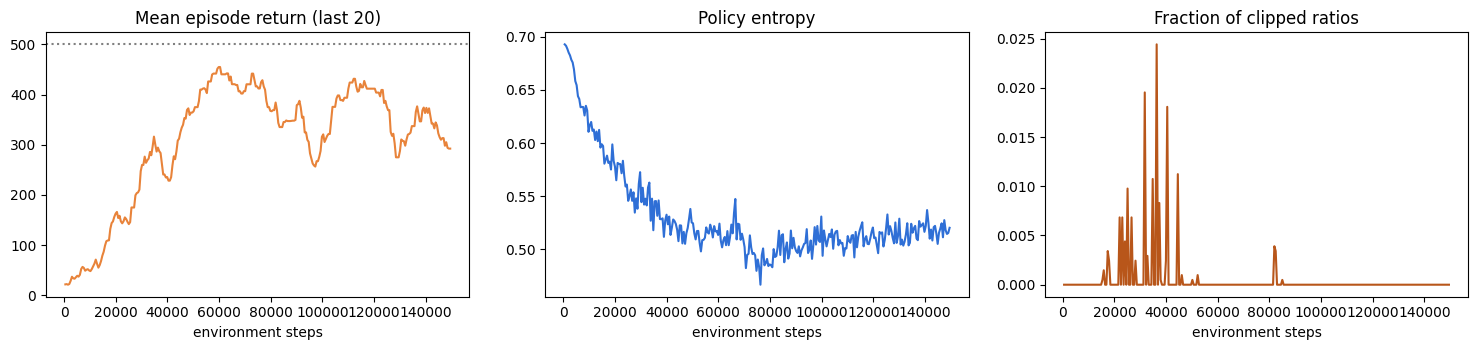

In [22]:
agent, hist = train()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(hist["step"], hist["mean_return"], color="#E8833A"); axes[0].axhline(500, ls=":", color="gray")
axes[0].set_title("Mean episode return (last 20)"); axes[0].set_xlabel("environment steps")
axes[1].plot(hist["step"], hist["entropy"], color="#2F6FD6"); axes[1].set_title("Policy entropy")
axes[2].plot(hist["step"], hist["clipfrac"], color="#B8561A"); axes[2].set_title("Fraction of clipped ratios")
for ax in axes: ax.set_xlabel("environment steps")
plt.tight_layout(); plt.show()

In [23]:
# Evaluate the trained policy greedily (most likely action) on 10 fresh episodes
def evaluate(agent, env_id="CartPole-v1", episodes=10, seed=1000):
    env = gym.make(env_id); scores = []
    for ep in range(episodes):
        obs, _ = env.reset(seed=seed + ep); done, total = False, 0.0
        while not done:
            with torch.no_grad():
                logits = agent.actor(torch.tensor(obs, dtype=torch.float32))
            obs, r, term, trunc, _ = env.step(int(torch.argmax(logits)))
            total += r; done = term or trunc
        scores.append(total)
    env.close()
    return float(np.mean(scores)), float(np.std(scores))

mean_score, std_score = evaluate(agent)
print(f"Greedy evaluation: {mean_score:.1f} ± {std_score:.1f}")

Greedy evaluation: 486.5 ± 33.0


### TODO 7.1 — Experiment: the clip range $\varepsilon$  *(slides 17–22)*

Train three agents that differ only in `clip_coef`: **0.1**, **0.2** and **10.0** (10 is so large that the clip never acts — effectively the *unclipped* surrogate). To make the effect visible, also use `update_epochs=10` and `lr=1e-3` for all three (more aggressive reuse of each batch). Use `total_steps=100_000`.

Plot the three learning curves on one figure and report `approx_kl` and `clipfrac`.


=== clip_coef = 0.1 ===
step   12800 | mean return (last 20 ep)  227.6 | entropy 0.585 | clipfrac 0.049 | approx_kl 0.0010 |   1.5s
step   25600 | mean return (last 20 ep)  384.3 | entropy 0.564 | clipfrac 0.161 | approx_kl 0.0025 |   3.0s
step   38400 | mean return (last 20 ep)  494.1 | entropy 0.570 | clipfrac 0.015 | approx_kl 0.0005 |   4.4s
step   51200 | mean return (last 20 ep)  484.4 | entropy 0.504 | clipfrac 0.093 | approx_kl 0.0016 |   5.8s
step   64000 | mean return (last 20 ep)  500.0 | entropy 0.538 | clipfrac 0.037 | approx_kl 0.0011 |   7.2s
step   76800 | mean return (last 20 ep)  492.7 | entropy 0.562 | clipfrac 0.193 | approx_kl 0.0028 |   8.6s
step   89600 | mean return (last 20 ep)  496.5 | entropy 0.549 | clipfrac 0.000 | approx_kl 0.0000 |  10.0s
step   99840 | mean return (last 20 ep)  481.5 | entropy 0.547 | clipfrac 0.000 | approx_kl 0.0000 |  11.2s

=== clip_coef = 0.2 ===
step   12800 | mean return (last 20 ep)  257.1 | entropy 0.559 | clipfrac 0.079 | appr

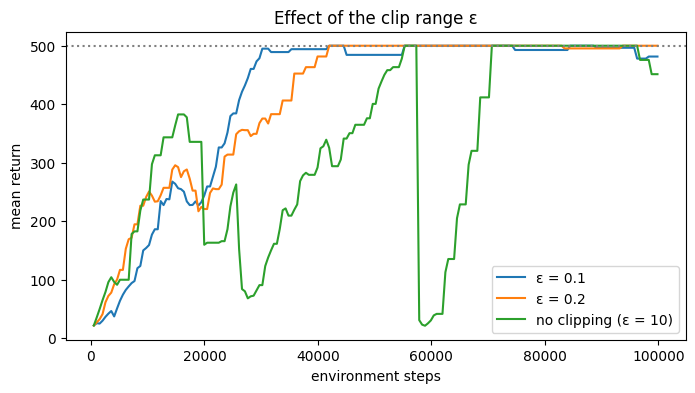

ε =  0.1: mean approx_kl = 0.0010, mean clipfrac = 0.050
ε =  0.2: mean approx_kl = 0.0023, mean clipfrac = 0.025
ε = 10.0: mean approx_kl = 0.0662, mean clipfrac = 0.000


In [24]:
# TODO 7.1 (solution)
eps_results = {}
for eps in [0.1, 0.2, 10.0]:
    print(f"\n=== clip_coef = {eps} ===")
    _, h = train(clip_coef=eps, update_epochs=10, lr=1e-3, total_steps=100_000)
    eps_results[eps] = h

plt.figure(figsize=(8, 4))
for eps, h in eps_results.items():
    label = f"ε = {eps}" if eps < 5 else "no clipping (ε = 10)"
    plt.plot(h["step"], h["mean_return"], label=label)
plt.axhline(500, ls=":", color="gray"); plt.xlabel("environment steps"); plt.ylabel("mean return")
plt.title("Effect of the clip range ε"); plt.legend(); plt.show()
for eps, h in eps_results.items():
    print(f"ε = {eps:>4}: mean approx_kl = {np.mean(h['approx_kl']):.4f}, mean clipfrac = {np.mean(h['clipfrac']):.3f}")

**Question 4 — model answer (what to look for; exact curves vary by seed and machine).**
* With **no clipping**, `approx_kl` is typically much larger: each batch is reused for 10 epochs at a high learning rate, so the policy drifts far from $\pi_{\theta_{old}}$. Learning curves tend to be **less stable** — fast early progress followed by drops or plateaus (the *cliff* of slide 17).
* **ε = 0.1** is the most conservative: small `approx_kl`, high `clipfrac`, usually steady but sometimes slower improvement.
* **ε = 0.2** is the usual compromise.
* `clipfrac` is the fraction of samples whose ratio left $[1-\varepsilon, 1+\varepsilon]$, i.e. where the clipped term won the `min` and the gradient was zero (cases 4–5).

> 🧑‍🏫 On an easy task like CartPole the unclipped run may still reach 500 for some seeds. If so, use it as a discussion point: run 2–3 seeds, or switch to LunarLander (Part 8), where the difference is clearer. Grade the *reasoning* linking KL/clipfrac to stability, not a specific curve.

### TODO 7.2 — Experiment: the GAE parameter $\lambda$  *(slides 13–14)*

Train three agents with `gae_lambda` = **0.0**, **0.95** and **1.0** (all other settings default, `total_steps=100_000`). Plot the learning curves on one figure.


=== gae_lambda = 0.0 ===
step   12800 | mean return (last 20 ep)   13.2 | entropy 0.578 | clipfrac 0.204 | approx_kl 0.0150 |   0.9s
step   25600 | mean return (last 20 ep)   42.6 | entropy 0.548 | clipfrac 0.000 | approx_kl 0.0000 |   1.8s
step   38400 | mean return (last 20 ep)   57.7 | entropy 0.523 | clipfrac 0.000 | approx_kl 0.0001 |   2.7s
step   51200 | mean return (last 20 ep)   60.0 | entropy 0.519 | clipfrac 0.000 | approx_kl 0.0004 |   3.6s
step   64000 | mean return (last 20 ep)  141.2 | entropy 0.538 | clipfrac 0.002 | approx_kl 0.0005 |   4.6s
step   76800 | mean return (last 20 ep)  182.8 | entropy 0.508 | clipfrac 0.000 | approx_kl 0.0000 |   5.5s
step   89600 | mean return (last 20 ep)  237.7 | entropy 0.504 | clipfrac 0.000 | approx_kl 0.0001 |   6.4s
step   99840 | mean return (last 20 ep)  209.6 | entropy 0.482 | clipfrac 0.000 | approx_kl 0.0000 |   7.1s

=== gae_lambda = 0.95 ===
step   12800 | mean return (last 20 ep)   80.7 | entropy 0.612 | clipfrac 0.000 | a

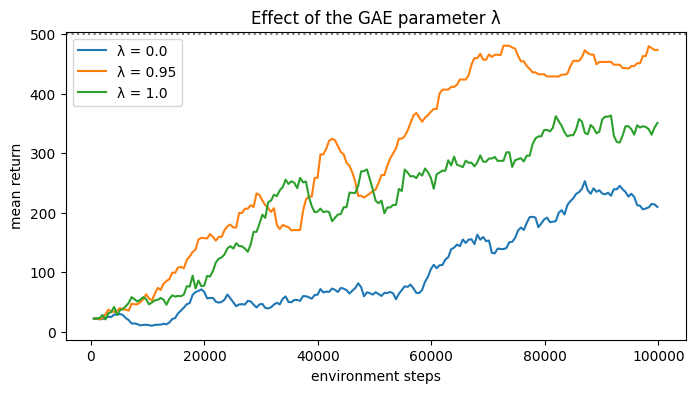

In [25]:
# TODO 7.2 (solution)
lam_results = {}
for lam in [0.0, 0.95, 1.0]:
    print(f"\n=== gae_lambda = {lam} ===")
    _, h = train(gae_lambda=lam, total_steps=100_000)
    lam_results[lam] = h

plt.figure(figsize=(8, 4))
for lam, h in lam_results.items():
    plt.plot(h["step"], h["mean_return"], label=f"λ = {lam}")
plt.axhline(500, ls=":", color="gray"); plt.xlabel("environment steps"); plt.ylabel("mean return")
plt.title("Effect of the GAE parameter λ"); plt.legend(); plt.show()

**Question 5 — model answer.**
* **λ = 0** (pure TD) relies entirely on the critic. Early in training the critic is poor, so the advantages are **biased** and learning is usually the slowest.
* **λ = 1** (Monte Carlo) uses the real returns: unbiased but **high-variance**; often learns, but more noisily.
* **λ = 0.95** blends both and is typically the fastest and most reliable — the "sweet spot" of the bias–variance spectrum (slide 13).
* Chess analogy: λ = 0 trusts the engine's instant evaluation; λ = 1 waits for the game result; λ = 0.95 mostly trusts what actually happened in the next many moves while still using the engine to fill in the rest.

---
## Part 8 · Optional challenge: LunarLander

Train the same code on `LunarLander-v3` (discrete actions, 8-dimensional state). It needs Box2D: `pip install "gymnasium[box2d]"` (on older Gymnasium versions the id is `LunarLander-v2`). Suggested settings: `total_steps=1_000_000, n_envs=8, n_steps=256, ent_coef=0.01`. An average return above **200** is considered solved. Then repeat the ε experiment of TODO 7.1.

```python
# agent_ll, hist_ll = train(env_id="LunarLander-v3", total_steps=1_000_000, n_envs=8, n_steps=256)
```

This is the environment used in the Hugging Face Deep RL Course, Unit 8 (hands-on with CleanRL).

---
## Reflection questions — model answers

**R1. Why does PPO store $\log\pi_{\theta_{old}}(a_t|s_t)$ during the rollout?**
Because it is the denominator of the ratio $r_t(\theta)$. After the first gradient step $\theta \neq \theta_{old}$, so the old probabilities can no longer be recomputed from the network.

**R2. What happens to the gradient in case 5 ($r > 1+\varepsilon$, $\hat A > 0$), and why is that desirable?**
It is zero: the clipped term $(1+\varepsilon)\hat A$ is a constant and wins the `min`. The action is already much more likely than before; pushing further could take a step "off the cliff". PPO "doesn't get too greedy".

**R3. Why can PPO run several epochs on the same batch while REINFORCE uses each episode once?**
REINFORCE's gradient is only valid for the policy that generated the data. PPO's surrogate re-weights the data by the ratio, and the clip removes the incentive to move far from $\pi_{\theta_{old}}$, so re-using the batch for $M$ epochs stays safe.

**R4. What does GAE reduce to when λ = 0? When λ = 1?**
λ = 0: the one-step TD error $\delta_t$. λ = 1: the Monte-Carlo advantage $G_t - V(s_t)$ (verified numerically in Question 2).

**R5. Why is PPO called *on-policy*, and why is the buffer discarded after each update?**
The update assumes the data comes from $\pi_{\theta_{old}}$, a policy close to the current one. After the update the policy has changed, so old data would make the ratios and advantages stale and the clip could no longer guarantee a safe step.

### Suggested grading
* Check cells: each TODO is worth its points if its check prints `PASSED` and the code follows the algorithm (no hard-coded answers).
* Part 7: 5 pts per experiment for correct runs and plots; 5 pts for the quality of the explanations in Questions 4–5.
* Questions 1–3 and R1–R5 can be used as an oral check or short quiz.

### References
* Hugging Face Deep RL Course — Unit 4 (Policy Gradient), Unit 6 (Actor-Critic), Unit 8 (PPO): https://huggingface.co/learn/deep-rl-course/unit8/introduction
* M. Hu, *The Art of Reinforcement Learning: Fundamentals, Mathematics, and Implementations with Python*, Apress, 2023 — Algorithm 21.
* J. Schulman et al., "High-Dimensional Continuous Control Using Generalized Advantage Estimation", 2015.
* J. Schulman et al., "Proximal Policy Optimization Algorithms", 2017.
* S. Huang et al., "The 37 Implementation Details of Proximal Policy Optimization", ICLR Blog Track, 2022 (CleanRL).